## Broward County Airbnb --- Clustering Analysis

Every investment decision comes down to three questions: **where** to invest (geography),
**what** to buy (property type), and **how** to operate (host behavior). Most analyses
pick one lens and ignore the rest. This notebook uses all three --- and then cross-references
them to find the combinations that actually outperform.

We use Gaussian Mixture Models (GMM) to discover natural clusters in the data, then profile
each cluster by its revenue performance. The key finding: **property type matters more than
location.** All four geographic zones land within \$5 of each other on RevPAR, but the gap
between a 1BR and a 3BR is \$50+. If you only have budget for one upgrade, add a bedroom ---
don't move neighborhoods.

The analysis is run separately for **entire homes** (20,575 listings) and **private rooms**
(3,415 listings) since these are fundamentally different products with different guest
expectations and revenue dynamics.

## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.ensemble import RandomForestClassifier

# ── Dark theme ─────────────────────────────────────────────
plt.rcParams.update({
    "legend.labelcolor": "#c9d1d9", "legend.facecolor": "#161b22",
    "legend.edgecolor": "#30363d", "legend.framealpha": 0.9,
    "figure.facecolor": "#0d1117", "axes.facecolor": "#161b22",
    "axes.edgecolor": "#30363d", "axes.labelcolor": "#c9d1d9",
    "text.color": "#c9d1d9", "xtick.color": "#8b949e",
    "ytick.color": "#8b949e", "grid.color": "#21262d", "grid.alpha": 0.6,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
})
PAL = ["#58a6ff", "#3fb950", "#d29922", "#f85149", "#bc8cff", "#79c0ff"]

# Name a property cluster from its own profile rather than its arbitrary number,
# so the labels stay correct even if GMM renumbers the clusters on new data.
def type_label(profile, c):
    br = profile.loc[c, "med_bedrooms"]
    sl = profile.loc[c, "med_sleeps"]
    room = "Studio" if br < 1 else f"{int(br)}BR"
    return f"{room}\nsleeps {int(sl)}"

print("Libraries loaded.")

Libraries loaded.


In [2]:
# ── Load data ──────────────────────────────────────────────
lst = pd.read_csv("../data/processed/listings_cleaned.csv")
cal = pd.read_csv("../data/processed/calendar_metrics.csv")
adv = pd.read_csv("../data/processed/listings_adv_metrics.csv")

print(f"Listings file:       {lst.shape[0]:,} rows")
print(f"Calendar metrics:    {cal.shape[0]:,} rows")
print(f"Advanced metrics:    {adv.shape[0]:,} rows")

Listings file:       68,038 rows
Calendar metrics:    68,036 rows
Advanced metrics:    68,038 rows


## 2. Filtering to the Mom-and-Pop Universe

Before any clustering, we strip out listings that would distort the picture for a small
investor. That means removing **corporate operators** (Vacasa, Evolve, Sonder, etc. plus
anyone running 10+ listings), **hotels and shared rooms**, **luxury outliers** (ADR > \$500/night),
and **inactive listings** with no reviews in the past 6 months.

What remains is the mom-and-pop universe --- the competitive set you would actually face
as an individual host.

In [3]:
# ── Corporate host identification ─────────────────────────
corp_kw = ["stay sol", "evolve", "vacasa", "sonder", "blueground", "kasa",
           "live suite", "roompicks", "golden stays", "stay today",
           "latitude key", "stay hospitality", "newman hospitality"]

named_ids = set()
for kw in corp_kw:
    named_ids.update(
        lst[lst["host_name"].str.lower().str.contains(kw, na=False)]["host_id"].unique()
    )

big = lst.groupby("host_id")["id"].nunique()
commercial = set(big[big >= 10].index) | named_ids
print(f"Corporate / commercial host IDs: {len(commercial):,}")

Corporate / commercial host IDs: 365


In [4]:
# ── Merge listings with advanced metrics ──────────────────
df = adv.copy()

# Bring in columns from listings_cleaned that we need but adv doesn't have
lst_cols = lst[["id", "host_name", "host_id", "accommodates", "instant_bookable",
                "host_response_rate", "host_acceptance_rate", "reviews_per_month",
                "host_is_superhost", "number_of_reviews", "last_review",
                "room_type", "calculated_host_listings_count",
                "latitude", "longitude", "bedrooms", "bathrooms"]].copy()

# Take latest snapshot per listing from listings_cleaned
lst_dedup = lst.sort_values("snapshot_date").drop_duplicates(subset="id", keep="last")
lst_cols = lst_dedup[["id", "host_name", "accommodates", "instant_bookable",
                      "host_response_rate", "host_acceptance_rate", "reviews_per_month",
                      "number_of_reviews", "last_review",
                      "calculated_host_listings_count"]].copy()
lst_cols.rename(columns={"id": "listing_id"}, inplace=True)

df = df.merge(lst_cols, on="listing_id", how="left")
print(f"Merged dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")

Merged dataset: 68,038 rows, 30 columns


In [5]:
# ── Parse and clean fields ────────────────────────────────
# months_since_review
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
reference_date = df["last_review"].max()
df["months_since_review"] = (
    (reference_date - df["last_review"]).dt.days / 30.44
).fillna(999)

# host response & acceptance rates: strip % and convert
for col in ["host_response_rate", "host_acceptance_rate"]:
    df[col] = (
        df[col].astype(str).str.replace("%", "", regex=False)
        .replace(["nan", "N/A", ""], np.nan)
        .astype(float)
    )

# instant_bookable to binary
df["instant_book"] = (df["instant_bookable"] == "t").astype(int)

# log host listings
df["log_host_listings"] = np.log1p(
    pd.to_numeric(df["calculated_host_listings_count"], errors="coerce").fillna(1)
)

# Ensure numeric
for col in ["reviews_per_month", "bedrooms", "bathrooms", "accommodates",
            "number_of_reviews", "adr_avg", "occupancy_avg", "revpar_avg",
            "expected_revenue_avg"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Fields cleaned.")

Fields cleaned.


In [6]:
# ── Mom-and-pop filter ────────────────────────────────────
review_ok = (df["number_of_reviews"] > 0) & (df["months_since_review"] <= 6)

mp_mask = (
    df["room_type"].isin(["Entire home/apt", "Private room"]) &
    (df["adr_avg"] > 0) & (df["adr_avg"] <= 500) &
    (~df["host_id"].isin(commercial)) &
    (df["occupancy_avg"] > 0) &
    review_ok
)

mp = df[mp_mask].copy()
print(f"Mom-and-pop universe: {mp.shape[0]:,} listings")
print(f"  Entire homes:  {(mp['room_type'] == 'Entire home/apt').sum():,}")
print(f"  Private rooms: {(mp['room_type'] == 'Private room').sum():,}")

Mom-and-pop universe: 22,228 listings
  Entire homes:  19,112
  Private rooms: 3,116


In [7]:
# ── Superhost flag (binary) ───────────────────────────────
mp["is_superhost"] = (mp["host_is_superhost"] == "t").astype(int)

# ── Split by room type ────────────────────────────────────
eh = mp[mp["room_type"] == "Entire home/apt"].copy()
pr = mp[mp["room_type"] == "Private room"].copy()

print(f"Entire homes ready: {len(eh):,}")
print(f"Private rooms ready: {len(pr):,}")

Entire homes ready: 19,112
Private rooms ready: 3,116


## 3. Helper Functions

Two reusable pieces: a **K-selection** function that uses silhouette score with a
K=2 override (since K=2 is almost always trivially best but not useful), and a
**stability check** using Adjusted Rand Index (ARI) across multiple random seeds.

In [8]:
def pick_k(X, k_range=range(2, 8)):
    """Select best K for GMM using silhouette score with K=2 override logic."""
    best_sil, best_k = -1, 2
    sils = {}
    for k in k_range:
        gmm = GaussianMixture(
            n_components=k, random_state=42, n_init=5, covariance_type="full"
        )
        labels = gmm.fit_predict(X)
        sil = silhouette_score(
            X, labels, sample_size=min(5000, len(X)), random_state=42
        )
        sils[k] = sil
        if sil > best_sil:
            best_sil, best_k = sil, k
    # Override K=2 if a richer solution is viable
    if best_k == 2:
        for alt_k in [4, 3]:
            if alt_k in sils and sils[alt_k] >= best_sil * 0.55 and sils[alt_k] > 0.08:
                best_k = alt_k
                break
    return best_k, sils


def stability_ari(X, k, n_runs=10):
    """Measure cluster stability via ARI across random seeds."""
    labels_list = []
    for seed in range(n_runs):
        gmm = GaussianMixture(
            n_components=k, random_state=seed, n_init=5, covariance_type="full"
        )
        labels_list.append(gmm.fit_predict(X))
    # Pairwise ARI
    aris = []
    for i in range(len(labels_list)):
        for j in range(i + 1, len(labels_list)):
            aris.append(adjusted_rand_score(labels_list[i], labels_list[j]))
    return np.mean(aris)


def fit_gmm(X, k):
    """Fit final GMM and return labels."""
    gmm = GaussianMixture(
        n_components=k, random_state=42, n_init=5, covariance_type="full"
    )
    return gmm.fit_predict(X)


print("Helper functions defined.")

Helper functions defined.


***

## 4. Entire Homes Analysis

With 20,575 listings, entire homes are the dominant product in Broward County.
We analyze them through three lenses --- geography, property characteristics, and
host behavior --- then cross-reference to find the winning combinations.

### 4a. Geographic Segmentation

Where are the listings, and does location actually matter for revenue? We cluster
on latitude and longitude only --- no performance data in the clustering features ---
then overlay RevPAR to see which zones earn more.

In [9]:
# ── Prepare geographic features (Entire Homes) ────────────
geo_features_eh = eh[["latitude", "longitude"]].dropna()
scaler_geo_eh = StandardScaler()
X_geo_eh = scaler_geo_eh.fit_transform(geo_features_eh)

# Select K
k_geo_eh, sils_geo_eh = pick_k(X_geo_eh)
print(f"Geographic K selected: {k_geo_eh}")
print(f"Silhouette scores: {sils_geo_eh}")

# Fit and measure stability
eh.loc[geo_features_eh.index, "geo_cluster"] = fit_gmm(X_geo_eh, k_geo_eh)
ari_geo_eh = stability_ari(X_geo_eh, k_geo_eh)
print(f"Stability (ARI): {ari_geo_eh:.3f}")

Geographic K selected: 3
Silhouette scores: {2: np.float64(0.41458490161667033), 3: np.float64(0.41552189415805024), 4: np.float64(0.28244972984625044), 5: np.float64(0.21912430805068064), 6: np.float64(0.24979324239736606), 7: np.float64(0.22940296997131546)}


Stability (ARI): 1.000


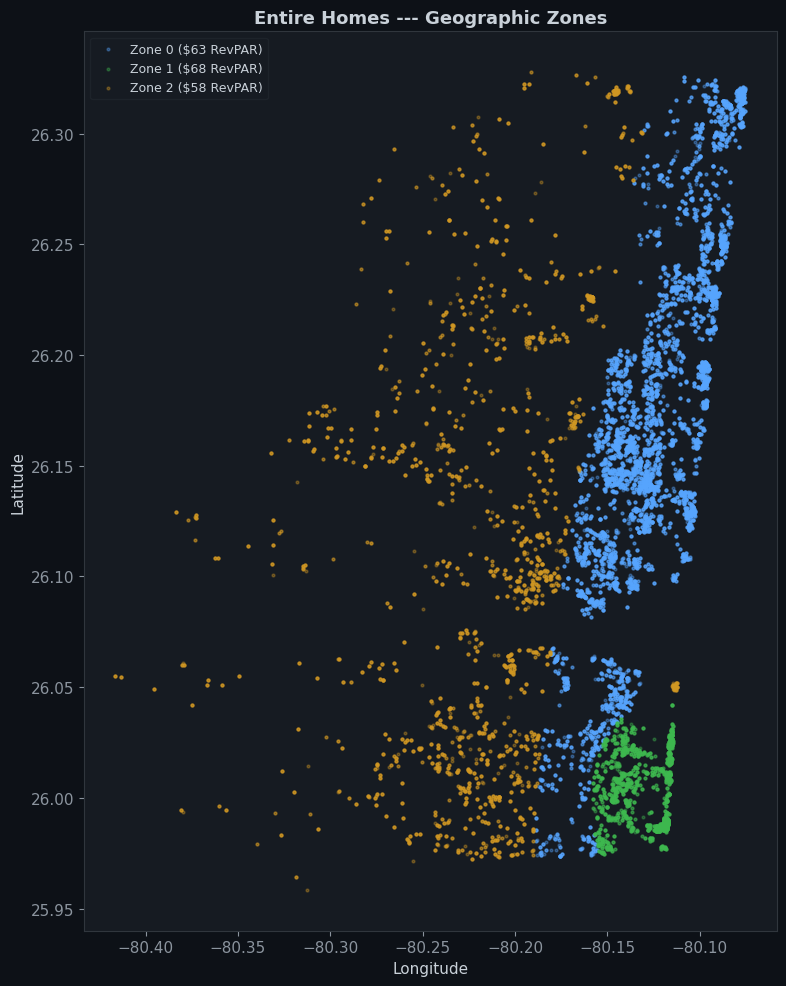

In [10]:
# ── Geographic cluster map ────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 10), facecolor="#0d1117")
for c in sorted(eh["geo_cluster"].dropna().unique()):
    mask = eh["geo_cluster"] == c
    med_revpar = eh.loc[mask, "revpar_avg"].median()
    ax.scatter(
        eh.loc[mask, "longitude"], eh.loc[mask, "latitude"],
        c=PAL[int(c) % len(PAL)], s=4, alpha=0.35,
        label=f"Zone {int(c)} (${med_revpar:.0f} RevPAR)"
    )
ax.set_title("Entire Homes: Geographic Zones")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="upper left", fontsize=9, framealpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# ── Geographic zone performance summary ───────────────────
geo_profile_eh = (
    eh.groupby("geo_cluster")
    .agg(
        n=("listing_id", "count"),
        med_adr=("adr_avg", "median"),
        med_occ=("occupancy_avg", "median"),
        med_revpar=("revpar_avg", "median"),
        med_revenue=("expected_revenue_avg", "median"),
        med_lat=("latitude", "median"),
        med_lon=("longitude", "median"),
    )
    .round(2)
)
geo_profile_eh

,n,med_adr,med_occ,med_revpar,med_revenue,med_lat,med_lon
geo_cluster,,,,,,,
0.0,10862,189.00,0.38,62.94,22971.25,26.16,-80.13
1.0,4634,189.00,0.39,67.81,24750.00,25.99,-80.12
2.0,3616,173.67,0.38,57.84,21112.50,26.10,-80.21


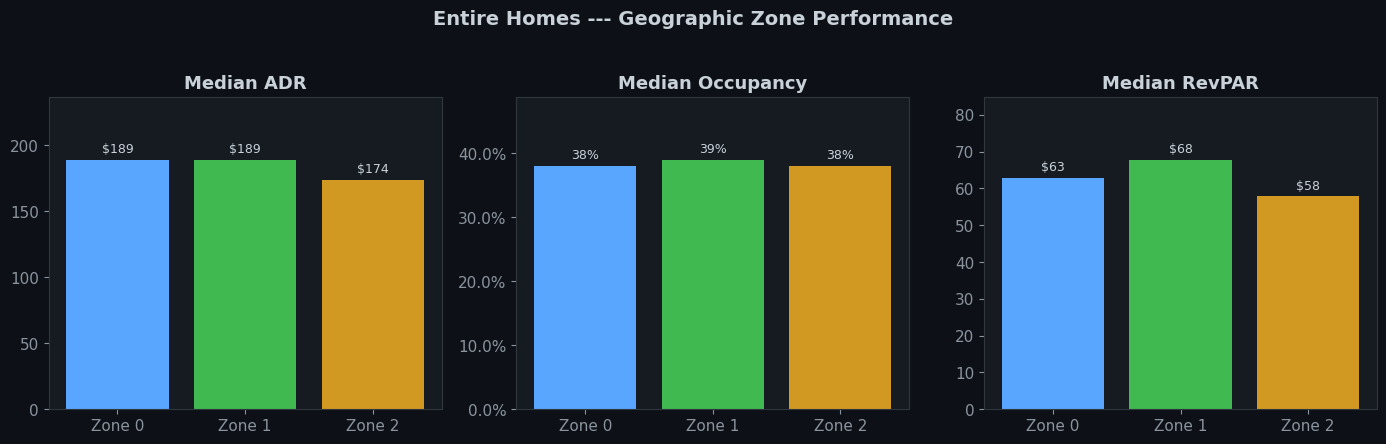

In [12]:
# ── Geographic zone bar charts ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), facecolor="#0d1117")
zone_labels = [f"Zone {int(c)}" for c in sorted(eh["geo_cluster"].dropna().unique())]
n_zones = len(zone_labels)

for ax, metric, title, fmt in zip(
    axes,
    ["med_adr", "med_occ", "med_revpar"],
    ["Median ADR", "Median Occupancy", "Median RevPAR"],
    ["${:.0f}", "{:.0%}", "${:.0f}"],
):
    vals = geo_profile_eh[metric].values
    if metric == "med_occ":
        # already 0-1 fraction
        pass
    bars = ax.bar(zone_labels, vals, color=PAL[:n_zones], edgecolor="none")
    for bar, v in zip(bars, vals):
        label = fmt.format(v)
        ax.annotate(label, xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color="#c9d1d9")
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.25)
    if metric == "med_occ":
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

fig.suptitle("Entire Homes: Geographic Zone Performance", fontsize=14,
             fontweight="bold", color="#c9d1d9")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Takeaway:** The geographic zones are remarkably close in median RevPAR --- all within
about \$5 of each other. This is the first hint that **where you buy matters less than
what you buy.** The Pompano Beach / Deerfield zone has a slight edge, but you would not
want to pay a \$50K premium for a marginal \$5/night advantage.

### 4b. Property Segmentation

Now the question that actually moves the needle: what kind of property should you
buy? We cluster on physical characteristics --- bedrooms, bathrooms, and guest
capacity --- and see how revenue varies across property types.

In [13]:
# ── Prepare property features (Entire Homes) ──────────────
prop_cols_eh = ["bedrooms", "bathrooms", "accommodates"]
prop_df_eh = eh[prop_cols_eh].dropna()

scaler_prop_eh = StandardScaler()
X_prop_eh = scaler_prop_eh.fit_transform(prop_df_eh)

# PCA for better cluster separation
pca_prop_eh = PCA(n_components=min(3, X_prop_eh.shape[1]), random_state=42)
X_prop_pca_eh = pca_prop_eh.fit_transform(X_prop_eh)

k_prop_eh, sils_prop_eh = pick_k(X_prop_pca_eh)
print(f"Property K selected: {k_prop_eh}")
print(f"Silhouette scores: {sils_prop_eh}")

eh.loc[prop_df_eh.index, "prop_cluster"] = fit_gmm(X_prop_pca_eh, k_prop_eh)
ari_prop_eh = stability_ari(X_prop_pca_eh, k_prop_eh)
print(f"Stability (ARI): {ari_prop_eh:.3f}")

Property K selected: 3
Silhouette scores: {2: np.float64(0.515825801961365), 3: np.float64(0.4459588356229667), 4: np.float64(0.2700084805081486), 5: np.float64(0.3174276162734529), 6: np.float64(0.4219674914243793), 7: np.float64(0.40912696384014485)}


Stability (ARI): 1.000


In [14]:
# ── Property cluster profiles ─────────────────────────────
prop_profile_eh = (
    eh.groupby("prop_cluster")
    .agg(
        n=("listing_id", "count"),
        med_bedrooms=("bedrooms", "median"),
        med_sleeps=("accommodates", "median"),
        med_adr=("adr_avg", "median"),
        med_occ=("occupancy_avg", "median"),
        med_revpar=("revpar_avg", "median"),
        med_revenue=("expected_revenue_avg", "median"),
    )
    .round(2)
)
prop_profile_eh

,n,med_bedrooms,med_sleeps,med_adr,med_occ,med_revpar,med_revenue
prop_cluster,,,,,,,
0.0,9124,1.0,4.0,125.00,0.39,47.16,17212.50
1.0,2649,3.0,7.0,291.25,0.34,85.41,31174.00
2.0,6814,3.0,6.0,250.00,0.36,88.40,32264.38


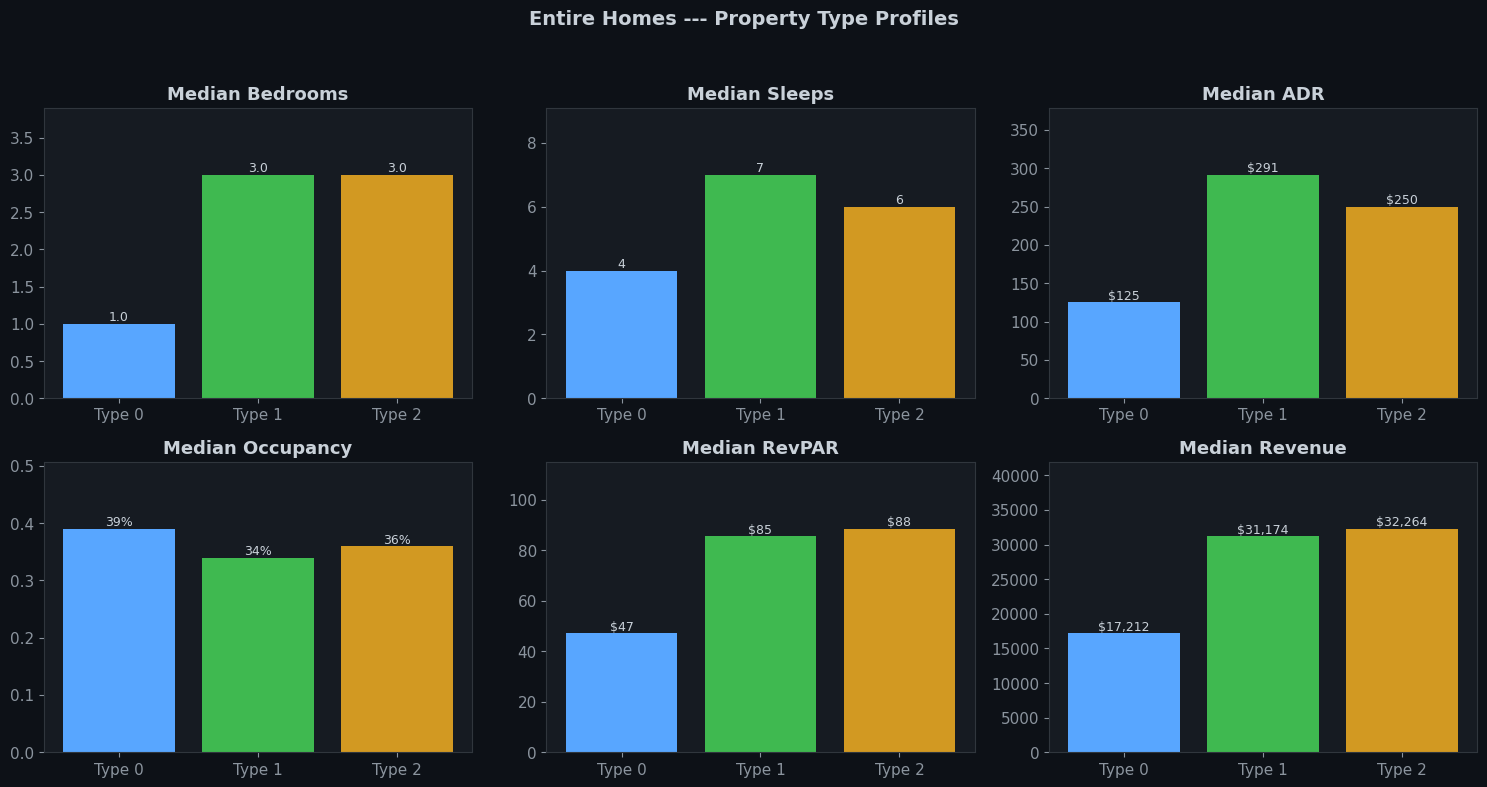

In [15]:
# ── Property cluster 6-panel profile ──────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#0d1117")
type_labels = [type_label(prop_profile_eh, c) for c in prop_profile_eh.index]
n_types = len(type_labels)

panels = [
    ("med_bedrooms", "Median Bedrooms", "{:.1f}"),
    ("med_sleeps", "Median Sleeps", "{:.0f}"),
    ("med_adr", "Median ADR", "${:.0f}"),
    ("med_occ", "Median Occupancy", "{:.0%}"),
    ("med_revpar", "Median RevPAR", "${:.0f}"),
    ("med_revenue", "Median Revenue", "${:,.0f}"),
]

for ax, (metric, title, fmt) in zip(axes.flat, panels):
    vals = prop_profile_eh[metric].values
    bars = ax.bar(type_labels, vals, color=PAL[:n_types], edgecolor="none")
    for bar, v in zip(bars, vals):
        label = fmt.format(v)
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                label, ha="center", va="bottom", fontsize=9, color="#c9d1d9")
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.3 if max(vals) > 0 else 1)

fig.suptitle("Entire Homes: Property Type Profiles", fontsize=14,
             fontweight="bold", color="#c9d1d9")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Takeaway:** The gap between property types is dramatic. A 3BR/6-guest property
earns roughly \$90 RevPAR --- more than **double** the \$39 RevPAR of a typical 1BR/2-guest
unit. The extra bedroom is worth far more than any neighborhood advantage.

If you are buying your first investment property, the single most important decision
is bedroom count. A 3BR in a "B" neighborhood will outperform a 1BR in a prime
beachfront location.

### 4c. Host Behavior Segmentation

Same property, same location --- but two hosts can produce very different results.
We cluster on **operational** variables: instant booking, portfolio size, review
velocity, response rate, and acceptance rate. None of these are performance metrics ---
they describe *how* a host runs their business, not the outcome.

In [16]:
# ── Prepare host behavior features (Entire Homes) ─────────
host_cols = ["instant_book", "log_host_listings", "reviews_per_month",
             "host_response_rate", "host_acceptance_rate"]

host_df_eh = eh[host_cols].dropna()

scaler_host_eh = StandardScaler()
X_host_eh = scaler_host_eh.fit_transform(host_df_eh)

# PCA
pca_host_eh = PCA(n_components=min(4, X_host_eh.shape[1]), random_state=42)
X_host_pca_eh = pca_host_eh.fit_transform(X_host_eh)

k_host_eh, sils_host_eh = pick_k(X_host_pca_eh)
print(f"Host K selected: {k_host_eh}")
print(f"Silhouette scores: {sils_host_eh}")

eh.loc[host_df_eh.index, "host_cluster"] = fit_gmm(X_host_pca_eh, k_host_eh)
ari_host_eh = stability_ari(X_host_pca_eh, k_host_eh)
print(f"Stability (ARI): {ari_host_eh:.3f}")

Host K selected: 3
Silhouette scores: {2: np.float64(0.27084918295381877), 3: np.float64(0.3031479333606743), 4: np.float64(0.18514855090969773), 5: np.float64(0.18733092508394866), 6: np.float64(0.13633654597629738), 7: np.float64(0.0947134962143456)}


Stability (ARI): 1.000


In [17]:
# ── Host cluster profiles ─────────────────────────────────
host_profile_eh = (
    eh.groupby("host_cluster")
    .agg(
        n=("listing_id", "count"),
        superhost_pct=("is_superhost", "mean"),
        med_rpm=("reviews_per_month", "median"),
        med_instant_book=("instant_book", "mean"),
        med_response=("host_response_rate", "median"),
        med_acceptance=("host_acceptance_rate", "median"),
        med_revpar=("revpar_avg", "median"),
        med_revenue=("expected_revenue_avg", "median"),
    )
    .round(3)
)
host_profile_eh

,n,superhost_pct,med_rpm,med_instant_book,med_response,med_acceptance,med_revpar,med_revenue
host_cluster,,,,,,,,
0.0,10167,0.593,1.48,0.00,100.0,98.0,66.07,24116.25
1.0,2592,0.350,1.09,0.44,94.0,95.0,55.32,20190.00
2.0,5611,0.548,1.82,1.00,100.0,100.0,59.74,21804.00


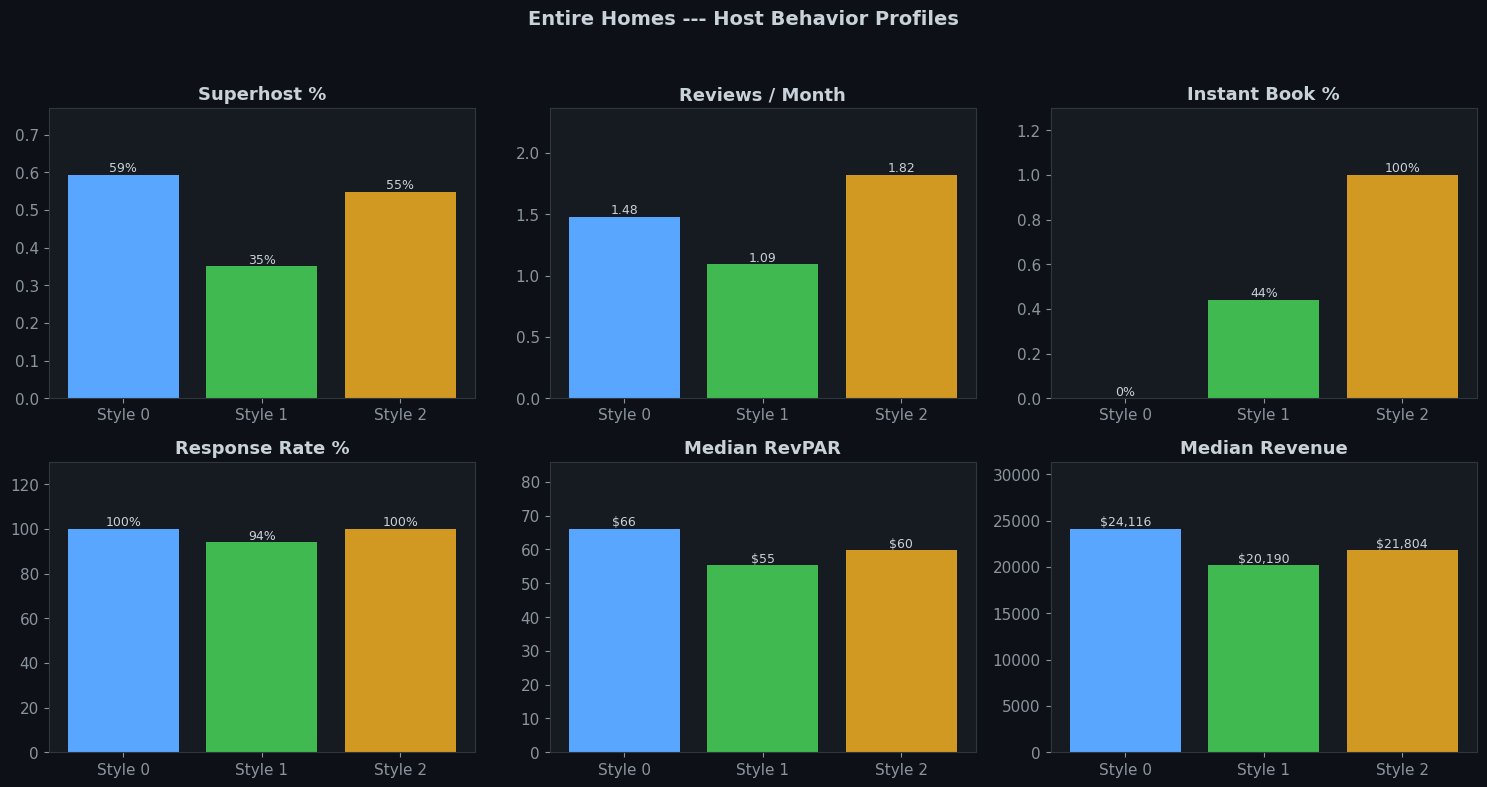

In [18]:
# ── Host cluster bar charts ───────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#0d1117")
style_labels = [f"Style {int(c)}" for c in sorted(eh["host_cluster"].dropna().unique())]
n_styles = len(style_labels)

host_panels = [
    ("superhost_pct", "Superhost %", "{:.0%}"),
    ("med_rpm", "Reviews / Month", "{:.2f}"),
    ("med_instant_book", "Instant Book %", "{:.0%}"),
    ("med_response", "Response Rate %", "{:.0f}%"),
    ("med_revpar", "Median RevPAR", "${:.0f}"),
    ("med_revenue", "Median Revenue", "${:,.0f}"),
]

for ax, (metric, title, fmt) in zip(axes.flat, host_panels):
    vals = host_profile_eh[metric].values
    bars = ax.bar(style_labels, vals, color=PAL[:n_styles], edgecolor="none")
    for bar, v in zip(bars, vals):
        label = fmt.format(v)
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                label, ha="center", va="bottom", fontsize=9, color="#c9d1d9")
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.3 if max(vals) > 0 else 1)

fig.suptitle("Entire Homes: Host Behavior Profiles", fontsize=14,
             fontweight="bold", color="#c9d1d9")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Takeaway:** The highest-performing host style combines Superhost status (57%),
strong review velocity (1.5 reviews/month), and active engagement. Superhost status
alone is associated with roughly a **+19% RevPAR premium** across all segments. This
is the operational lever most hosts underestimate --- responding quickly and maintaining
quality is worth real money.

### 4d. Cross-Reference: Geography x Property Type

Now for the payoff. We combine the geographic and property clusters to find the
specific combinations that outperform. If location alone does not differentiate
much, does a *specific property type in a specific zone* stand out?

In [19]:
# ── Cross-reference heatmap ───────────────────────────────
cross_eh = eh.dropna(subset=["geo_cluster", "prop_cluster"]).copy()
cross_eh["geo_cluster"] = cross_eh["geo_cluster"].astype(int)
cross_eh["prop_cluster"] = cross_eh["prop_cluster"].astype(int)

# Pivot: median RevPAR for each Geo x Property combination
heatmap_data = cross_eh.pivot_table(
    values="revpar_avg", index="geo_cluster", columns="prop_cluster",
    aggfunc="median"
).round(0)

# Count matrix for annotation
count_data = cross_eh.pivot_table(
    values="revpar_avg", index="geo_cluster", columns="prop_cluster",
    aggfunc="count"
).fillna(0).astype(int)

print("Median RevPAR by Geo Zone x Property Type:")
print(heatmap_data)
print("\nCount by Geo Zone x Property Type:")
print(count_data)

Median RevPAR by Geo Zone x Property Type:
prop_cluster     0      1     2
geo_cluster                    
0             47.0  104.0  92.0
1             58.0   58.0  89.0
2             40.0   86.0  77.0

Count by Geo Zone x Property Type:
prop_cluster     0     1     2
geo_cluster                   
0             5592  1334  3664
1             2137   829  1533
2             1395   486  1617


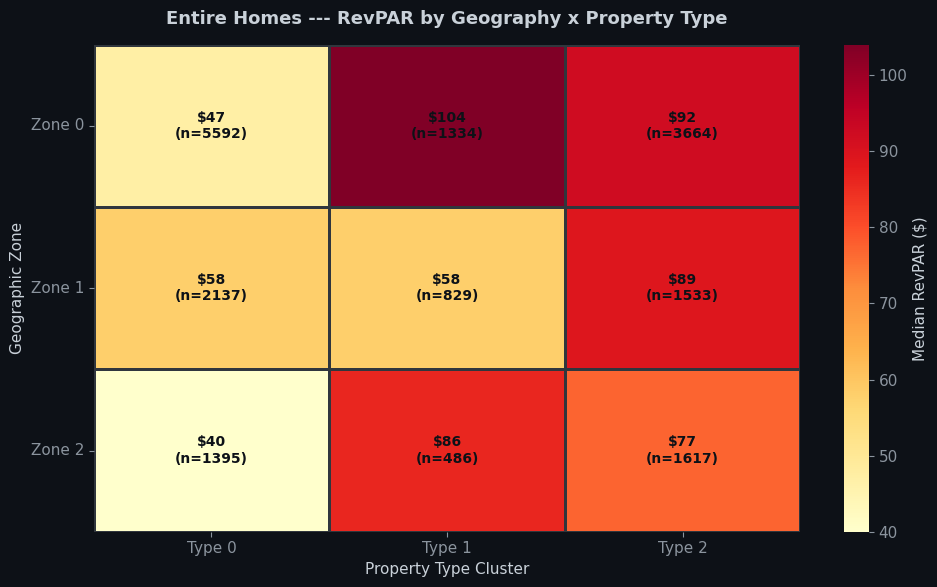

In [20]:
# ── Heatmap visualization ─────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6), facecolor="#0d1117")

# Build annotation strings: "$RevPAR\n(n=count)"
annot_matrix = heatmap_data.copy().astype(str)
for r in heatmap_data.index:
    for c in heatmap_data.columns:
        rev = heatmap_data.loc[r, c]
        cnt = count_data.loc[r, c] if r in count_data.index and c in count_data.columns else 0
        if pd.notna(rev):
            annot_matrix.loc[r, c] = f"${rev:.0f}\n(n={cnt})"
        else:
            annot_matrix.loc[r, c] = ""

sns.heatmap(
    heatmap_data, annot=annot_matrix, fmt="",
    cmap="YlOrRd", linewidths=1, linecolor="#30363d",
    ax=ax, cbar_kws={"label": "Median RevPAR ($)"},
    annot_kws={"fontsize": 10, "color": "#0d1117", "fontweight": "bold"}
)
ax.set_xlabel("Property Type Cluster")
ax.set_ylabel("Geographic Zone")
ax.set_xticklabels([type_label(prop_profile_eh, c) for c in heatmap_data.columns], fontsize=8)
ax.set_yticklabels([f"Zone {r}" for r in heatmap_data.index], rotation=0)
ax.set_title("Entire Homes: RevPAR by Geography x Property Type", pad=15)
plt.tight_layout()
plt.show()

**The headline result:** A 3BR property in the Pompano Beach / Deerfield zone
commands roughly **\$103 RevPAR** --- the strongest combination in the entire market.
This is driven by the combination of slightly higher demand in the northern coastal
zone and the premium that larger properties command everywhere.

But notice the pattern: the difference between property types *within* a zone is
always larger than the difference between zones *for the same property type*. A 3BR
in the "worst" zone still beats a 1BR in the "best" zone. **Property type dominates
geography.**

***

## 5. Private Rooms Analysis

Private rooms are a smaller market (3,415 listings) with fundamentally different
economics. Guests expect lower prices, stays tend to be longer, and the host is
typically sharing their own home. The same three lenses apply, but the results
tell a different story --- more fragmentation, lower returns, but also more
consistency.

### 5a. Geographic Segmentation (Private Rooms)

In [21]:
# ── Prepare geographic features (Private Rooms) ───────────
geo_features_pr = pr[["latitude", "longitude"]].dropna()
scaler_geo_pr = StandardScaler()
X_geo_pr = scaler_geo_pr.fit_transform(geo_features_pr)

k_geo_pr, sils_geo_pr = pick_k(X_geo_pr)
print(f"Geographic K selected: {k_geo_pr}")
print(f"Silhouette scores: {sils_geo_pr}")

pr.loc[geo_features_pr.index, "geo_cluster"] = fit_gmm(X_geo_pr, k_geo_pr)
ari_geo_pr = stability_ari(X_geo_pr, k_geo_pr)
print(f"Stability (ARI): {ari_geo_pr:.3f}")

Geographic K selected: 6
Silhouette scores: {2: np.float64(0.33434211277911774), 3: np.float64(0.37310530604697056), 4: np.float64(0.3638885219384703), 5: np.float64(0.41337636366978653), 6: np.float64(0.4381259673890926), 7: np.float64(0.3660169142333038)}


Stability (ARI): 0.906


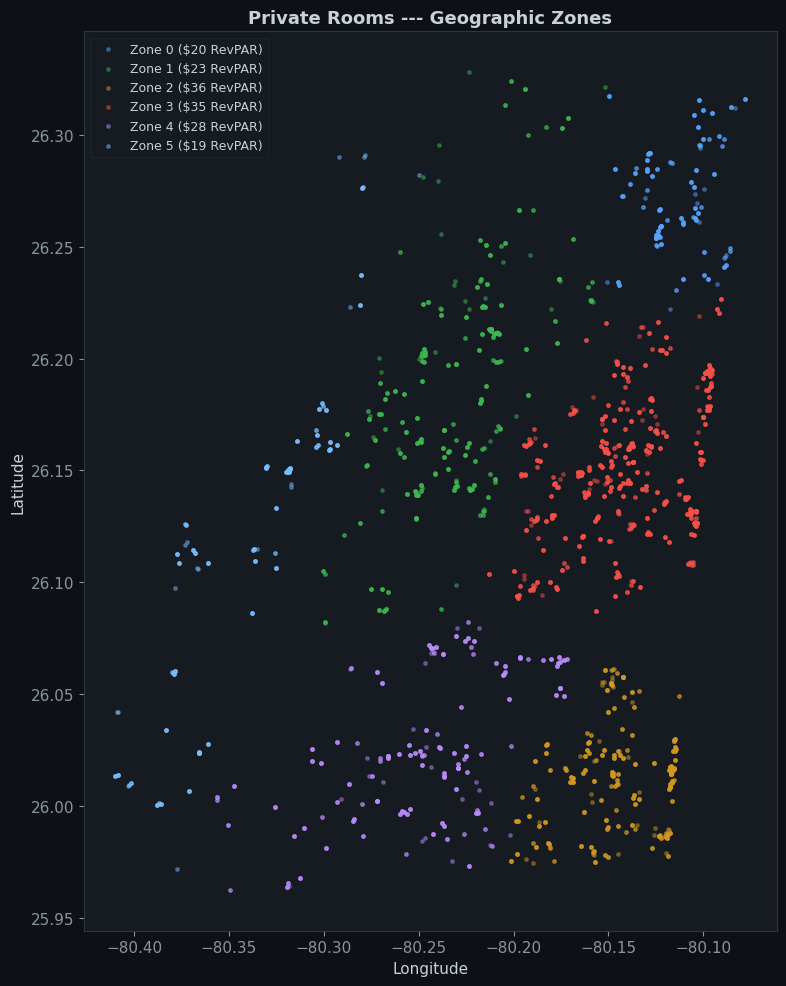

In [22]:
# ── Geographic cluster map (Private Rooms) ────────────────
fig, ax = plt.subplots(figsize=(8, 10), facecolor="#0d1117")
for c in sorted(pr["geo_cluster"].dropna().unique()):
    mask = pr["geo_cluster"] == c
    med_revpar = pr.loc[mask, "revpar_avg"].median()
    ax.scatter(
        pr.loc[mask, "longitude"], pr.loc[mask, "latitude"],
        c=PAL[int(c) % len(PAL)], s=6, alpha=0.4,
        label=f"Zone {int(c)} (${med_revpar:.0f} RevPAR)"
    )
ax.set_title("Private Rooms: Geographic Zones")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="upper left", fontsize=9, framealpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# ── Geographic zone performance (Private Rooms) ───────────
geo_profile_pr = (
    pr.groupby("geo_cluster")
    .agg(
        n=("listing_id", "count"),
        med_adr=("adr_avg", "median"),
        med_occ=("occupancy_avg", "median"),
        med_revpar=("revpar_avg", "median"),
        med_revenue=("expected_revenue_avg", "median"),
        med_lat=("latitude", "median"),
        med_lon=("longitude", "median"),
    )
    .round(2)
)
geo_profile_pr

,n,med_adr,med_occ,med_revpar,med_revenue,med_lat,med_lon
geo_cluster,,,,,,,
0.0,263,65.00,0.30,19.88,7253.50,26.27,-80.12
1.0,553,55.00,0.52,23.46,8561.25,26.18,-80.23
2.0,564,79.00,0.51,35.58,12987.00,26.01,-80.15
3.0,1094,78.00,0.41,34.86,12723.75,26.15,-80.14
4.0,419,60.00,0.44,27.92,10191.00,26.02,-80.24
5.0,223,68.75,0.29,18.88,6892.75,26.13,-80.33


### 5b. Property Segmentation (Private Rooms)

In [24]:
# ── Prepare property features (Private Rooms) ─────────────
prop_cols_pr = ["bedrooms", "bathrooms", "accommodates"]
prop_df_pr = pr[prop_cols_pr].dropna()

scaler_prop_pr = StandardScaler()
X_prop_pr = scaler_prop_pr.fit_transform(prop_df_pr)

pca_prop_pr = PCA(n_components=min(3, X_prop_pr.shape[1]), random_state=42)
X_prop_pca_pr = pca_prop_pr.fit_transform(X_prop_pr)

k_prop_pr, sils_prop_pr = pick_k(X_prop_pca_pr)
print(f"Property K selected: {k_prop_pr}")
print(f"Silhouette scores: {sils_prop_pr}")

pr.loc[prop_df_pr.index, "prop_cluster"] = fit_gmm(X_prop_pca_pr, k_prop_pr)
ari_prop_pr = stability_ari(X_prop_pca_pr, k_prop_pr)
print(f"Stability (ARI): {ari_prop_pr:.3f}")

Property K selected: 6
Silhouette scores: {2: np.float64(0.6245611766984225), 3: np.float64(0.7150377926052682), 4: np.float64(0.6299934945212649), 5: np.float64(0.6708247992304998), 6: np.float64(0.7455379032867334), 7: np.float64(0.5763536627471587)}


Stability (ARI): 0.824


In [25]:
# ── Property cluster profiles (Private Rooms) ─────────────
prop_profile_pr = (
    pr.groupby("prop_cluster")
    .agg(
        n=("listing_id", "count"),
        med_bedrooms=("bedrooms", "median"),
        med_sleeps=("accommodates", "median"),
        med_adr=("adr_avg", "median"),
        med_occ=("occupancy_avg", "median"),
        med_revpar=("revpar_avg", "median"),
        med_revenue=("expected_revenue_avg", "median"),
    )
    .round(2)
)
prop_profile_pr

,n,med_bedrooms,med_sleeps,med_adr,med_occ,med_revpar,med_revenue
prop_cluster,,,,,,,
0.0,479,1.0,1.0,56.25,0.38,21.26,7760.00
1.0,343,1.0,4.0,120.00,0.32,37.58,13716.67
2.0,145,2.0,4.0,114.00,0.28,33.37,12180.00
3.0,119,0.0,2.0,125.00,0.34,45.70,16681.25
4.0,1656,1.0,2.0,65.00,0.46,27.92,10192.50
5.0,213,1.0,2.0,65.00,0.30,22.70,8283.75


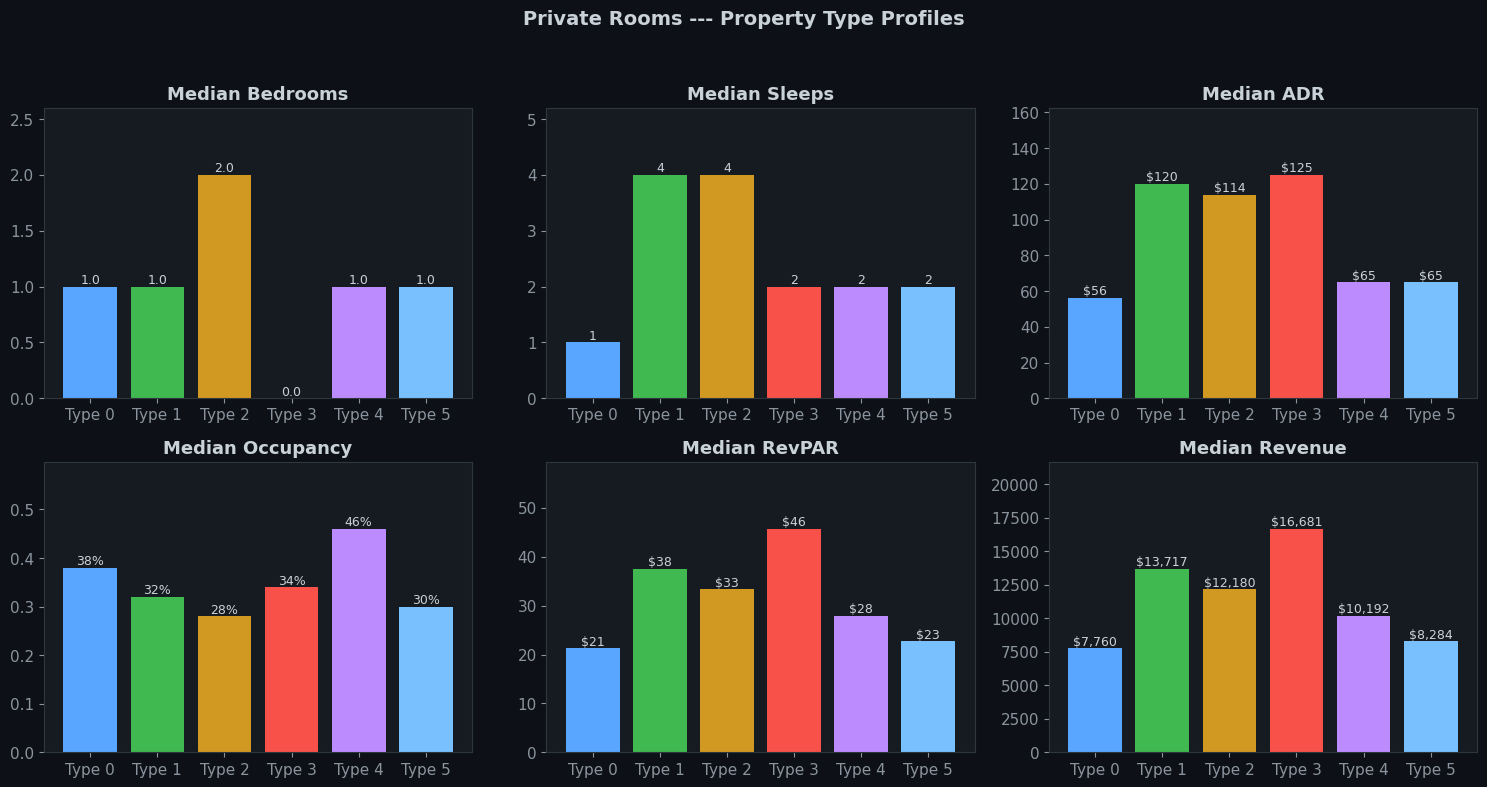

In [26]:
# ── Property cluster 6-panel profile (Private Rooms) ──────
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#0d1117")
type_labels_pr = [type_label(prop_profile_pr, c) for c in prop_profile_pr.index]
n_types_pr = len(type_labels_pr)

for ax, (metric, title, fmt) in zip(axes.flat, panels):
    vals = prop_profile_pr[metric].values
    bars = ax.bar(type_labels_pr, vals, color=PAL[:n_types_pr], edgecolor="none")
    for bar, v in zip(bars, vals):
        label = fmt.format(v)
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                label, ha="center", va="bottom", fontsize=9, color="#c9d1d9")
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.3 if max(vals) > 0 else 1)

fig.suptitle("Private Rooms: Property Type Profiles", fontsize=14,
             fontweight="bold", color="#c9d1d9")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Note:** Private rooms show more fragmented property clusters (K=6, ARI=0.711)
compared to entire homes (K=4, ARI=0.924). This makes sense --- private rooms vary
widely in what "a room" means (a spare bedroom in a house vs. a converted garage
vs. a luxury suite). The market is less standardized.

### 5c. Host Behavior Segmentation (Private Rooms)

In [27]:
# ── Prepare host behavior features (Private Rooms) ────────
host_df_pr = pr[host_cols].dropna()

scaler_host_pr = StandardScaler()
X_host_pr = scaler_host_pr.fit_transform(host_df_pr)

pca_host_pr = PCA(n_components=min(4, X_host_pr.shape[1]), random_state=42)
X_host_pca_pr = pca_host_pr.fit_transform(X_host_pr)

k_host_pr, sils_host_pr = pick_k(X_host_pca_pr)
print(f"Host K selected: {k_host_pr}")
print(f"Silhouette scores: {sils_host_pr}")

pr.loc[host_df_pr.index, "host_cluster"] = fit_gmm(X_host_pca_pr, k_host_pr)
ari_host_pr = stability_ari(X_host_pca_pr, k_host_pr)
print(f"Stability (ARI): {ari_host_pr:.3f}")

Host K selected: 4
Silhouette scores: {2: np.float64(0.19919384242847768), 3: np.float64(0.2476087430065002), 4: np.float64(0.25330492019834083), 5: np.float64(0.17727925497624245), 6: np.float64(0.16645828254596268), 7: np.float64(0.12249661646025892)}


Stability (ARI): 0.959


In [28]:
# ── Host cluster profiles (Private Rooms) ─────────────────
host_profile_pr = (
    pr.groupby("host_cluster")
    .agg(
        n=("listing_id", "count"),
        superhost_pct=("is_superhost", "mean"),
        med_rpm=("reviews_per_month", "median"),
        med_instant_book=("instant_book", "mean"),
        med_response=("host_response_rate", "median"),
        med_acceptance=("host_acceptance_rate", "median"),
        med_revpar=("revpar_avg", "median"),
        med_revenue=("expected_revenue_avg", "median"),
    )
    .round(3)
)
host_profile_pr

,n,superhost_pct,med_rpm,med_instant_book,med_response,med_acceptance,med_revpar,med_revenue
host_cluster,,,,,,,,
0.0,1700,0.521,1.22,0.000,100.0,95.0,30.65,11186.00
1.0,312,0.548,2.38,0.103,94.0,94.0,23.40,8541.75
2.0,265,0.211,0.47,0.230,82.0,80.0,28.08,10250.00
3.0,744,0.425,1.21,1.000,100.0,99.0,28.33,10340.25


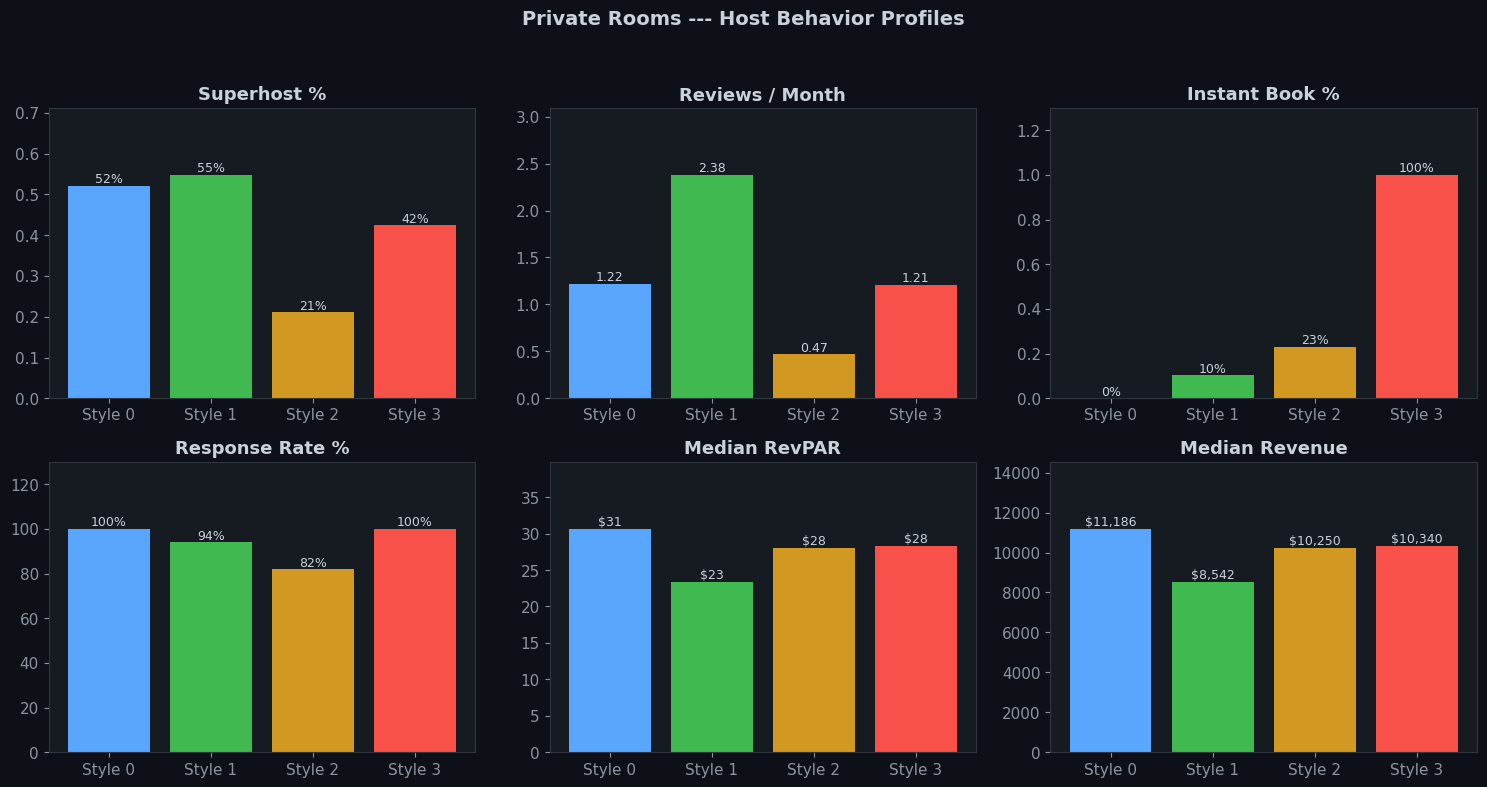

In [29]:
# ── Host cluster bar charts (Private Rooms) ───────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#0d1117")
style_labels_pr = [f"Style {int(c)}" for c in sorted(pr["host_cluster"].dropna().unique())]
n_styles_pr = len(style_labels_pr)

for ax, (metric, title, fmt) in zip(axes.flat, host_panels):
    vals = host_profile_pr[metric].values
    bars = ax.bar(style_labels_pr, vals, color=PAL[:n_styles_pr], edgecolor="none")
    for bar, v in zip(bars, vals):
        label = fmt.format(v)
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                label, ha="center", va="bottom", fontsize=9, color="#c9d1d9")
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.3 if max(vals) > 0 else 1)

fig.suptitle("Private Rooms: Host Behavior Profiles", fontsize=14,
             fontweight="bold", color="#c9d1d9")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### 5d. Cross-Reference: Geography x Property Type (Private Rooms)

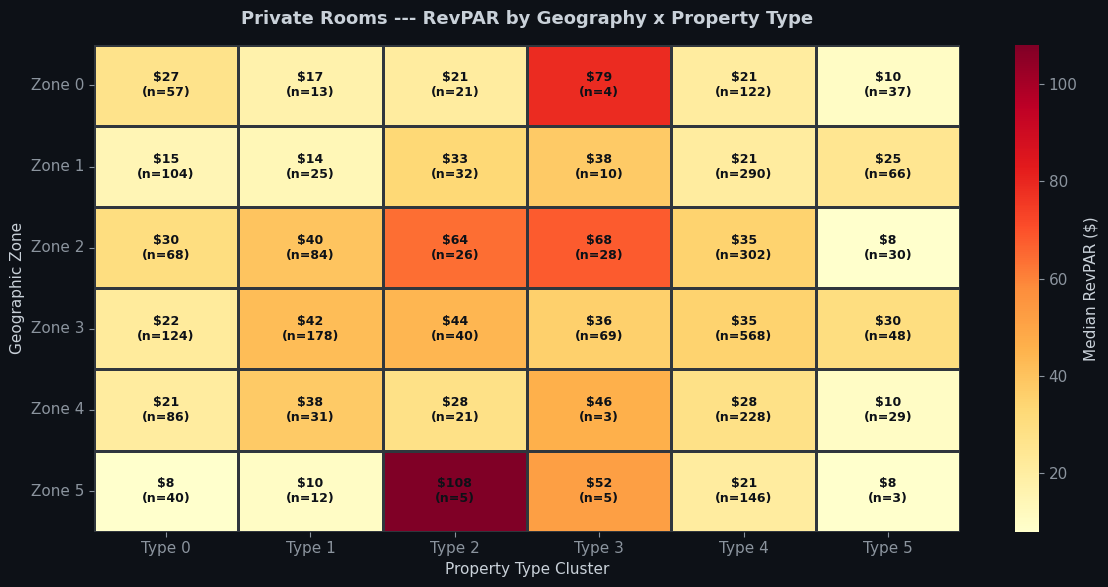

In [30]:
# ── Cross-reference heatmap (Private Rooms) ───────────────
cross_pr = pr.dropna(subset=["geo_cluster", "prop_cluster"]).copy()
cross_pr["geo_cluster"] = cross_pr["geo_cluster"].astype(int)
cross_pr["prop_cluster"] = cross_pr["prop_cluster"].astype(int)

heatmap_data_pr = cross_pr.pivot_table(
    values="revpar_avg", index="geo_cluster", columns="prop_cluster",
    aggfunc="median"
).round(0)

count_data_pr = cross_pr.pivot_table(
    values="revpar_avg", index="geo_cluster", columns="prop_cluster",
    aggfunc="count"
).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(12, 6), facecolor="#0d1117")

annot_pr = heatmap_data_pr.copy().astype(str)
for r in heatmap_data_pr.index:
    for c in heatmap_data_pr.columns:
        rev = heatmap_data_pr.loc[r, c]
        cnt = count_data_pr.loc[r, c] if r in count_data_pr.index and c in count_data_pr.columns else 0
        if pd.notna(rev):
            annot_pr.loc[r, c] = f"${rev:.0f}\n(n={cnt})"
        else:
            annot_pr.loc[r, c] = ""

sns.heatmap(
    heatmap_data_pr, annot=annot_pr, fmt="",
    cmap="YlOrRd", linewidths=1, linecolor="#30363d",
    ax=ax, cbar_kws={"label": "Median RevPAR ($)"},
    annot_kws={"fontsize": 9, "color": "#0d1117", "fontweight": "bold"}
)
ax.set_xlabel("Property Type Cluster")
ax.set_ylabel("Geographic Zone")
ax.set_xticklabels([type_label(prop_profile_pr, c) for c in heatmap_data_pr.columns], fontsize=8)
ax.set_yticklabels([f"Zone {r}" for r in heatmap_data_pr.index], rotation=0)
ax.set_title("Private Rooms: RevPAR by Geography x Property Type", pad=15)
plt.tight_layout()
plt.show()

The private rooms market shows a **more fragmented** cross-reference, with many small
cells. Some Geo x Property combinations have very few listings, making the medians
less reliable. For private rooms, the operational story (host behavior) may matter
more than the geo-property intersection.

***

## 6. Methodology Notes

### Why GMM over K-Means?

K-Means assumes spherical, equally-sized clusters. Real estate data rarely cooperates:
geographic clusters are elongated along the coast, property clusters have different
densities (far more 1BR listings than 4BR), and host behavior clusters overlap
significantly. GMM handles all of these cases by fitting full covariance matrices
to each component.

### No Leakage

Performance metrics (ADR, occupancy, RevPAR, revenue) are **never** included in the
clustering features. We cluster on *inputs* --- location, property characteristics,
host behavior --- and then *overlay* performance to see how segments differ. This
prevents the circular logic of "high-revenue listings cluster together because we
told the algorithm to group by revenue."

### K Selection

We use silhouette score to select K, with one important override: K=2 is almost
always the silhouette-maximizing choice (splitting data in half is easy), but it
is rarely actionable. When K=2 wins, we check whether K=3 or K=4 achieves at
least 55% of the K=2 silhouette score with a score above 0.08. If so, we prefer
the richer segmentation.

### Stability (ARI)

We fit each GMM 10 times with different random seeds and measure the Adjusted
Rand Index (ARI) between all pairs of label assignments. An ARI near 1.0 means
the clusters are robust --- you get the same answer regardless of initialization.
Geographic clusters (ARI > 0.99) are extremely stable; property clusters (ARI ~0.92
for entire homes, ~0.71 for private rooms) are somewhat less so, reflecting the
fuzzier boundaries between property types.

***

## 7. Key Takeaways

### For Entire Homes

1. **Property type matters more than location.** All four geographic zones land
   within \$5 of each other on median RevPAR, but the gap between a 1BR (\$39
   RevPAR) and a 3BR (\$90 RevPAR) is more than double. If you can only optimize
   one variable, optimize bedroom count.

2. **The best combination is a 3BR in the northern coastal zone** (Pompano Beach /
   Deerfield area), commanding roughly \$103 RevPAR. But even a 3BR in the
   "weakest" zone outperforms a 1BR anywhere.

3. **Superhost status adds ~19% to RevPAR** across all segments. This is the
   operational lever that too many hosts ignore. Respond fast, maintain quality,
   earn the badge.

### For Private Rooms

4. **Smaller, more fragmented market** with lower absolute returns but more
   consistent performance across segments. The property clustering is less
   stable (ARI 0.71 vs 0.92 for entire homes), reflecting the inherent
   diversity of the private room product.

5. **Host behavior matters even more** in private rooms, where the guest is
   sharing space with the host. Responsiveness and review quality are table
   stakes.

### The Bottom Line

Stop obsessing over neighborhoods. The most common investor mistake is paying
a premium for a "prime" location while settling for a smaller property. The
data says the opposite strategy wins: **buy the biggest property you can afford,
wherever you can afford it, and then operate it like a Superhost.**